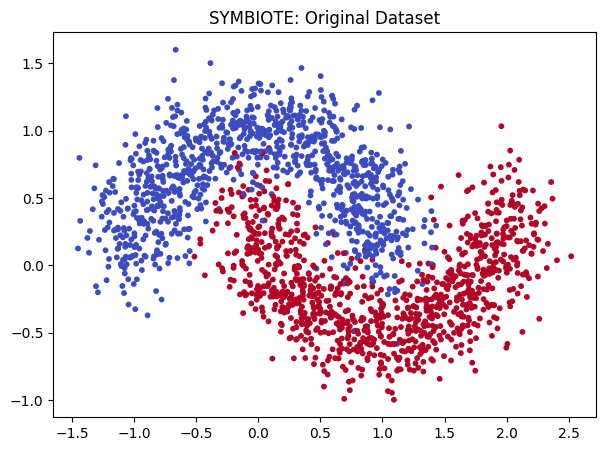

In [7]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Generate dataset
X, y = make_moons(
    n_samples=2000,
    noise=0.2,
    random_state=42
)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Convert to tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

# Visualize
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=10)
plt.title("SYMBIOTE: Original Dataset")
plt.show()

In [16]:
class SymbioteNet(nn.Module):
  def __init__(self):
    super().__init__()

    self.network = nn.Sequential(
        nn.Linear(2, 32),
        nn.ReLU(),
        nn.Linear(32,32),
        nn.ReLU(),
        nn.Linear(32, 2)
    )
  def forward(self, x):
    return self.network(x)

In [17]:
model = SymbioteNet()
print(model)

SymbioteNet(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=2, bias=True)
  )
)


In [53]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr = 0.01)
epochs = 100

In [54]:
train_losses = []

for epoch in range(epochs):
  model.train()
  optimizer.zero_grad()

  outputs = model(X_train)
  loss = criterion(outputs, y_train)

  loss.backward()
  optimizer.step()
  train_losses.append(loss.item())

  if (epoch + 1) % 10 == 0:
    print(
        f"Epoch [{epoch+1}/{epochs}]",
        f"Loss: {loss.item():.4f}"
    )

Epoch [10/100] Loss: 4.8976
Epoch [20/100] Loss: 1.3193
Epoch [30/100] Loss: 0.6387
Epoch [40/100] Loss: 0.2927
Epoch [50/100] Loss: 0.1502
Epoch [60/100] Loss: 0.1011
Epoch [70/100] Loss: 0.0896
Epoch [80/100] Loss: 0.0832
Epoch [90/100] Loss: 0.0788
Epoch [100/100] Loss: 0.0772


In [55]:
model.eval()

with torch.no_grad():
  predictions = model(X_test).argmax(dim=1)
  accuracy = ((predictions == y_test).float().mean().item())

print(f"Healthy Model Accuracy: {accuracy * 100:.2f}%")

Healthy Model Accuracy: 96.50%


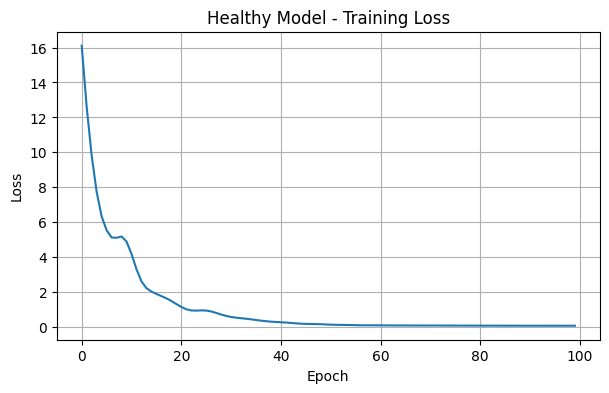

In [56]:
plt.figure(figsize=(7, 4))

plt.plot(train_losses)

plt.title("Healthy Model - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.grid()
plt.show()

In [57]:
import copy
healthy_weights = copy.deepcopy(model.state_dict())

In [58]:
def infect_model(model, healthy_weights, intensity):
  infected_weights = copy.deepcopy(healthy_weights)

  for key in infected_weights:
    noise = torch.randn_like(infected_weights[key])
    infected_weights[key] += intensity * noise

  model.load_state_dict(infected_weights)
  return model

In [59]:
infection_levels = [0.0, 0.05, 0.1, 0.2, 0.5, 1.0]
results = []

for intensity in infection_levels:
  infect_model(model, healthy_weights, intensity)
  model.eval()

  with torch.no_grad():
    predictions = model(X_test).argmax(dim=1)
    accuracy = ((predictions == y_test).float().mean().item())
    loss = critetrion(model(X_test), y_test).item()

  results.append({
      "infection": intensity,
      "accuracy": accuracy * 100,
      "loss": loss
  })

  print(
        f"Infection: {intensity:.2f} | "
        f"Accuracy: {accuracy * 100:.2f}% | "
        f"Loss: {loss:.4f}"
    )

Infection: 0.00 | Accuracy: 96.50% | Loss: 0.1137
Infection: 0.05 | Accuracy: 95.75% | Loss: 0.1395
Infection: 0.10 | Accuracy: 88.50% | Loss: 0.5502
Infection: 0.20 | Accuracy: 58.50% | Loss: 3.0233
Infection: 0.50 | Accuracy: 46.75% | Loss: 3.4754
Infection: 1.00 | Accuracy: 27.00% | Loss: 27.1222


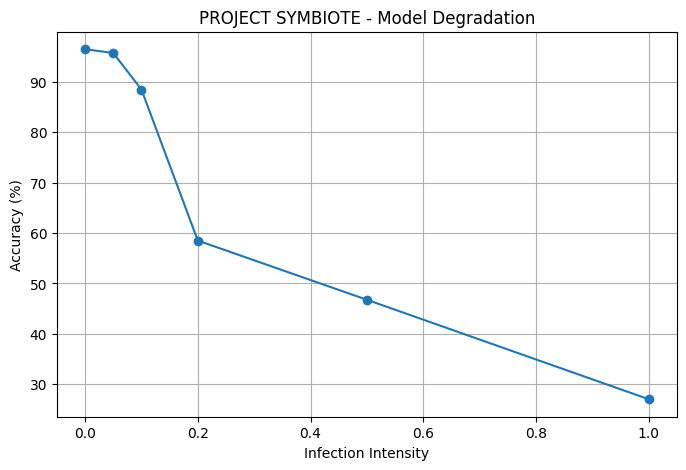

In [60]:
plt.figure(figsize=(8, 5))

plt.plot(
    [r["infection"] for r in results],
    [r["accuracy"] for r in results],
    marker="o"
)

plt.xlabel("Infection Intensity")
plt.ylabel("Accuracy (%)")
plt.title("PROJECT SYMBIOTE - Model Degradation")

plt.grid()
plt.show()

In [61]:
def plot_boundary(model, title):

    model.eval()

    x_min, x_max = -2, 3
    y_min, y_max = -1.5, 2

    xx, yy = torch.meshgrid(
        torch.linspace(x_min, x_max, 200),
        torch.linspace(y_min, y_max, 200),
        indexing="xy"
    )

    grid = torch.stack(
        [xx.flatten(), yy.flatten()],
        dim=1
    )

    with torch.no_grad():
        predictions = model(grid).argmax(dim=1)

    predictions = predictions.reshape(xx.shape)

    plt.figure(figsize=(8, 6))

    plt.contourf(
        xx.numpy(),
        yy.numpy(),
        predictions.numpy(),
        alpha=0.35,
        cmap="coolwarm"
    )

    plt.scatter(
        X_test[:, 0].numpy(),
        X_test[:, 1].numpy(),
        c=y_test.numpy(),
        cmap="coolwarm",
        edgecolors="black",
        s=15
    )

    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()

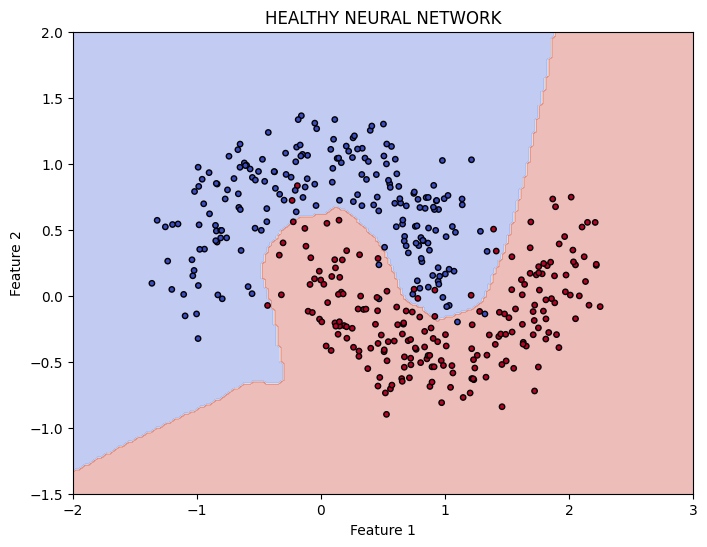

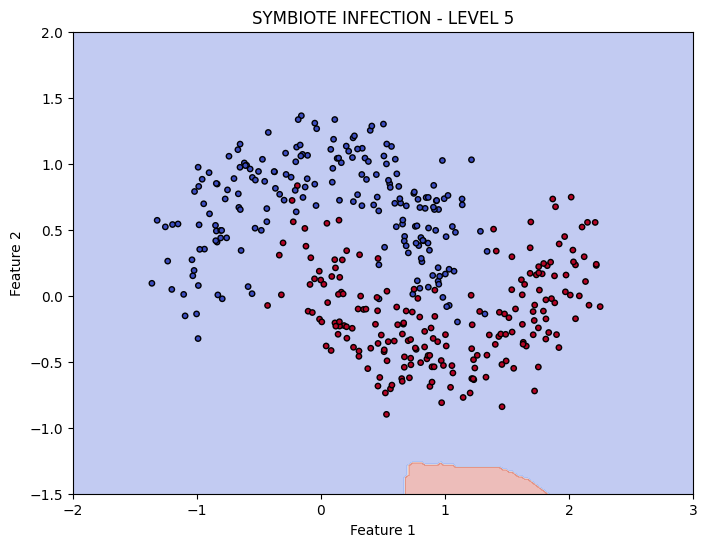

In [62]:
model.load_state_dict(healthy_weights)
plot_boundary(model, "HEALTHY NEURAL NETWORK")

infect_model(model, healthy_weights, 1.0)
plot_boundary(model, "SYMBIOTE INFECTION - LEVEL 5")

In [63]:
infected_model = SymbioteNet()
infected_model.load_state_dict(healthy_weights)
infect_model(infected_model, healthy_weights, intensity=0.5)

infected_model.eval()
with torch.no_grad():
  infected_predictions = infected_model(X_test).argmax(dim=1)
  infected_accuracy = ((infected_predictions == y_test).float().mean().item())

print(f"Infected Accuracy: {infected_accuracy * 100:.2f}%")

Infected Accuracy: 64.50%


In [64]:
recovery_optimizer = optim.Adam(
    infected_model.parameters(),
    lr=0.001
)

recovery_epochs = 100
recovery_losses = []
recovery_accuracies = []

for epoch in range(recovery_epochs):
    infected_model.train()
    recovery_optimizer.zero_grad()

    outputs = infected_model(X_train)
    loss = criterion(outputs, y_train)
    loss.backward()

    recovery_optimizer.step()
    recovery_losses.append(loss.item())

    infected_model.eval()
    with torch.no_grad():
        predictions = infected_model(X_test).argmax(dim=1)
        accuracy = ((predictions == y_test).float().mean().item())

    recovery_accuracies.append(accuracy * 100)

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch [{epoch+1}/{recovery_epochs}] | "
            f"Loss: {loss.item():.4f} | "
            f"Accuracy: {accuracy * 100:.2f}%"
        )

Epoch [10/100] | Loss: 14.7727 | Accuracy: 67.00%
Epoch [20/100] | Loss: 11.3304 | Accuracy: 69.75%
Epoch [30/100] | Loss: 8.2520 | Accuracy: 70.75%
Epoch [40/100] | Loss: 5.6333 | Accuracy: 73.00%
Epoch [50/100] | Loss: 3.6251 | Accuracy: 70.25%
Epoch [60/100] | Loss: 2.7415 | Accuracy: 62.00%
Epoch [70/100] | Loss: 2.1799 | Accuracy: 65.50%
Epoch [80/100] | Loss: 1.6912 | Accuracy: 72.75%
Epoch [90/100] | Loss: 1.3137 | Accuracy: 74.75%
Epoch [100/100] | Loss: 1.0181 | Accuracy: 76.00%


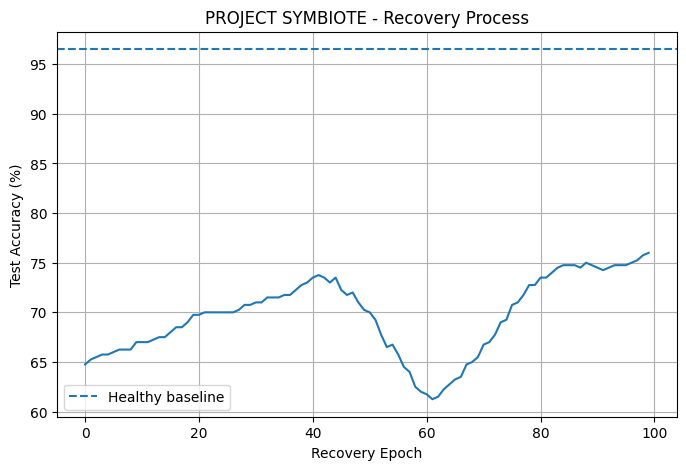

In [65]:
plt.figure(figsize=(8, 5))

plt.plot(recovery_accuracies)

plt.axhline(
    y=96.5,
    linestyle="--",
    label="Healthy baseline"
)

plt.xlabel("Recovery Epoch")
plt.ylabel("Test Accuracy (%)")

plt.title("PROJECT SYMBIOTE - Recovery Process")

plt.legend()
plt.grid()

plt.show()

In [70]:
healthy_acc = ((model.load_state_dict(healthy_weights) is None))
healthy_predictions = model(X_test).argmax(dim=1)
healthy_accuracy = ((healthy_predictions == y_test).float().mean().item() * 100)

recovered_predictions = infected_model(X_test).argmax(dim=1)
recovered_accuracy = ((recovered_predictions == y_test).float().mean().item() * 100
                      )
print(f"Healthy Model:   {healthy_accuracy:.2f}%")
print(f"Infected Model:  {infected_accuracy * 100:.2f}%")
print(f"Recovered Model: {recovered_accuracy:.2f}%")

Healthy Model:   96.50%
Infected Model:  64.50%
Recovered Model: 76.00%


In [71]:
infected_model.eval()

with torch.no_grad():

    outputs = infected_model(X_test)

    final_predictions = outputs.argmax(dim=1)

    final_accuracy = (
        (final_predictions == y_test)
        .float()
        .mean().item()
    )

print("Last curve accuracy:", recovery_accuracies[-1] * 100)
print("Fresh evaluation:", final_accuracy * 100)

Last curve accuracy: 7599.999904632568
Fresh evaluation: 75.99999904632568
